# Train Common Spatial Features Model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Colab deps (safe no-op locally)
import sys
if 'google.colab' in sys.modules:
    %pip install -q tensorflow scikit-learn

In [ ]:
# All imports
import os
import sys
import math
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [ ]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
!nvidia-smi

Sun Jan 18 18:25:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       2MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Paths & basic config (edit BASE_DIR if running on Colab)
BASE_DIR = '/content/drive/MyDrive/'
LABELED_EEG_DATA_DIR = Path(BASE_DIR) / 'labeled_eeg_data'
PRE_WINDOW_MS = 500
POST_WINDOW_MS = 500

DEFAULT_EEGNET_CHANNELS = ['F3', 'F4', 'F7', 'F8', 'Fz', 'FC1', 'FC2', 'FC5', 'FC6',
                          'Fp1', 'Fp2', 'Pz', 'P3', 'P4', 'P7', 'P8']


In [ ]:
USE_SUBJECTS = sorted([
    d.name for d in Path(LABELED_EEG_DATA_DIR).iterdir()
    if d.is_dir() and d.name.startswith('P')
])
print(f"Found {len(USE_SUBJECTS)} subjects: {USE_SUBJECTS[:10]} ...")


CHANNELS_TO_USE = ['F3', 'F4', 'Fz', 'FC1', 'Fp1', 'Fp2', 'Pz', 'P3', 'P4']
print(f"Using {len(CHANNELS_TO_USE)} channels: {CHANNELS_TO_USE}")


Found 16 subjects: ['P01', 'P05', 'P07', 'P09', 'P10', 'P12', 'P16', 'P17', 'P19', 'P20'] ...
Using 9 channels: ['F3', 'F4', 'Fz', 'FC1', 'Fp1', 'Fp2', 'Pz', 'P3', 'P4']


In [ ]:
# --------------------------
# SIMPLE EEG DATA LOADING
# --------------------------
def load_eeg_data(subjects, channels, pre_ms, post_ms):
    """Load EEG data for specified subjects and channels."""
    all_X, all_y = [], []

    for subject in subjects:
        file_path = LABELED_EEG_DATA_DIR / subject / f"{pre_ms}_{post_ms}_training_data.npz"
        if not file_path.exists():
            continue

        # Load with memory mapping first to check channels
        with np.load(file_path, mmap_mode='r') as data:
            ch_names = data['channel_names']

            # Find indices of channels we want
            ch_indices = []
            for ch in channels:
                if ch in ch_names:
                    ch_indices.append(list(ch_names).index(ch))

            if len(ch_indices) == 0:
                continue  # Skip if no channels found

            # Only load the data we need - much more memory efficient
            X_full = data['X']  # Still memory mapped
            y = data['y'][:]    # Load labels (small)

            # Extract only the channels we want
            X_selected = X_full[:, ch_indices, :].copy()  # Copy only needed data

        all_X.append(X_selected)
        all_y.append(y)

        # Force garbage collection to free memory
        del X_selected

    # Combine all subjects
    X_combined = np.concatenate(all_X, axis=0)
    y_combined = np.concatenate(all_y, axis=0)

    print(f"Loaded {X_combined.shape[0]} trials from {len(all_X)} subjects")
    print(f"Using {len(ch_indices)} channels, {X_combined.shape[2]} time points")

    # Add label distribution analysis
    label_counts = Counter(y_combined)
    total_samples = len(y_combined)
    print("\nLabel Distribution:")
    for label, count in sorted(label_counts.items()):
        proportion = count / total_samples
        print(f"  Label {label}: {count} samples ({proportion:.2%})")

    return X_combined, y_combined

## Look at Data

Loaded 3819 trials from 1 subjects
Using 1 channels, 500 time points

Label Distribution:
  Label False: 2084 samples (54.57%)
  Label True: 1735 samples (45.43%)

Statistics for a single trial (F3):
  Mean: -0.41
  Std: 4.20
  Min: -11.26
  Max: 12.00


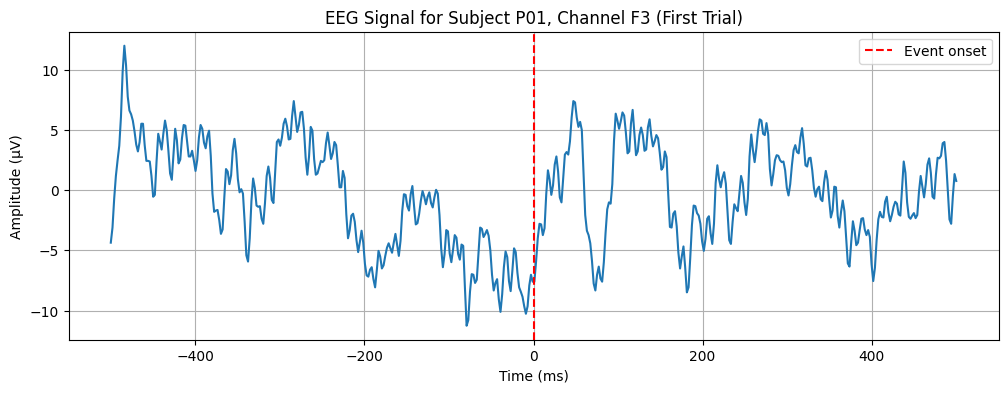

In [ ]:
# Select one subject and one channel for inspection
subject_to_inspect = USE_SUBJECTS[0] # Take the first subject
channel_to_inspect = CHANNELS_TO_USE[0] # Take the first channel, e.g., 'F3'

# Temporarily modify CHANNELS_TO_USE to load only the specific channel
original_channels = CHANNELS_TO_USE
CHANNELS_TO_USE = [channel_to_inspect]

X_single_subj_chan, y_single_subj_chan = load_eeg_data(
# Load data for only the selected subject and channel
    [subject_to_inspect],
    CHANNELS_TO_USE,
    PRE_WINDOW_MS,
    POST_WINDOW_MS
)

# Restore original CHANNELS_TO_USE
CHANNELS_TO_USE = original_channels

# Take the first trial (sample)
# The shape is (samples, channels, time_points), so for one channel it's (samples, 1, time_points)
eeg_signal = X_single_subj_chan[0, 0, :]

print(f"\nStatistics for a single trial ({channel_to_inspect}):")
print(f"  Mean: {np.mean(eeg_signal):.2f}")
print(f"  Std: {np.std(eeg_signal):.2f}")
print(f"  Min: {np.min(eeg_signal):.2f}")
print(f"  Max: {np.max(eeg_signal):.2f}")

num_samples = eeg_signal.shape[0]

# Generate time axis from -PRE_WINDOW_MS to POST_WINDOW_MS
time_axis_ms = np.linspace(-PRE_WINDOW_MS, POST_WINDOW_MS, num_samples)

# Plot the time series
plt.figure(figsize=(12, 4))
plt.plot(time_axis_ms, eeg_signal)
plt.title(f'EEG Signal for Subject {subject_to_inspect}, Channel {channel_to_inspect} (First Trial)')
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude (µV)')
plt.grid(True)
plt.axvline(x=0, color='r', linestyle='--', label='Event onset') # Mark event onset
plt.legend()
plt.show()

# CSP

In [ ]:
import numpy as np
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, roc_auc_score

In [ ]:
X, y = load_eeg_data(USE_SUBJECTS, CHANNELS_TO_USE, PRE_WINDOW_MS, POST_WINDOW_MS)
print(pd.Series(y).value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

X_train, X_test, y_train, y_test = X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y # Changed from np.argmax(y, axis=1) to y
    )

In [ ]:
import numpy as np
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, roc_auc_score

# Ensure labels are integers (0/1)
y_train = y_train.astype(int)
y_test = y_test.astype(int)

# --------------------------
# Define classifier
# --------------------------
clf = LinearDiscriminantAnalysis()

# --------------------------
# Build pipeline: CSP -> Scaler -> LDA
# Scaling CSP features is optional, but included here
# --------------------------
pipeline = Pipeline([
    ('csp', CSP(n_components=15, log=True, norm_trace=False)),
    ('scaler', StandardScaler()),  # scales CSP features
    ('clf', clf)
])

# --------------------------
# Train pipeline on training data
# CSP is fit only on X_train
# --------------------------
pipeline.fit(X_train, y_train)

In [ ]:
# --------------------------
# Predict on test data
# --------------------------
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# --------------------------
# Evaluate
# --------------------------
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Test Accuracy: {accuracy:.3f}")
print(f"Test ROC-AUC:  {auc:.3f}")

cm_svm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (SVM)")
plt.show()